# Predikcia dojazdu elektrických áut: analýza dát

**Cieľ projektu:** predpovedať dojazd elektrického auta (`range_km`) z jeho technických parametrov.

**Dáta:** databáza amerického úradu EPA ([fueleconomy.gov](https://www.fueleconomy.gov/feg/download.shtml)).
Skript `priprav_epa.py` z nej vyberie iba elektrické autá, z textového popisu motora vytiahne výkon
a počet motorov a prepočíta míle na kilometre. Výsledok je súbor `data/ev_epa.csv`.

| stĺpec | význam |
|---|---|
| `year` | modelový rok |
| `make`, `model` | značka a model |
| `vehicle_class` | trieda vozidla podľa EPA (malé SUV, veľké auto, pickup…) |
| `drive` | typ pohonu (predný, zadný, 4×4…) |
| `motor_kw` | celkový výkon motorov (kW) |
| `n_motors` | počet motorov |
| `charge_time_240v_hr` | čas nabíjania na 240 V (h), nepriamo vypovedá o veľkosti batérie |
| `kwh_per_100km` | spotreba (kWh/100 km) |
| `range_km` | **dojazd (km): cieľová premenná** |

## 1. Načítanie dát

In [149]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [150]:
df = pd.read_csv('data/ev_epa.csv')
df.head()

,year,make,model,vehicle_class,drive,motor_kw,n_motors,charge_time_240v_hr,kwh_per_100km,range_km
0,2000,Nissan,Altra EV,Midsize Station Wagons,NaN,62.0,1.0,NaN,24.85,145.0
1,2000,Toyota,RAV4 EV,Sport Utility Vehicle - 2WD,2-Wheel Drive,50.0,1.0,NaN,29.20,142.0
2,2001,Toyota,RAV4 EV,Sport Utility Vehicle - 2WD,2-Wheel Drive,50.0,1.0,NaN,29.20,142.0
3,2001,Ford,Th!nk,Two Seaters,NaN,27.0,1.0,NaN,32.31,47.0
4,2001,Ford,Explorer USPS Electric,Sport Utility Vehicle - 2WD,2-Wheel Drive,67.0,1.0,NaN,54.06,61.0


## 2. Základný prehľad

In [151]:
print('Počet riadkov a stĺpcov:', df.shape)
df.info()

Počet riadkov a stĺpcov: (1608, 10)
<class 'pandas.DataFrame'>
RangeIndex: 1608 entries, 0 to 1607
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   year                 1608 non-null   int64  
 1   make                 1608 non-null   str    
 2   model                1608 non-null   str    
 3   vehicle_class        1608 non-null   str    
 4   drive                1600 non-null   str    
 5   motor_kw             1395 non-null   float64
 6   n_motors             1557 non-null   float64
 7   charge_time_240v_hr  1584 non-null   float64
 8   kwh_per_100km        1608 non-null   float64
 9   range_km             1608 non-null   float64
dtypes: float64(5), int64(1), str(4)
memory usage: 125.8 KB


In [152]:
# pandas 3 načítava text ako typ 'str', nie 'object', preto sa pýtame, či je stĺpec číselný
cat_col = df.select_dtypes(exclude='number').columns.tolist()
num_col = df.select_dtypes(include='number').columns.tolist()

print('Kategorické stĺpce:', cat_col)
print('Číselné stĺpce:', num_col)

Kategorické stĺpce: ['make', 'model', 'vehicle_class', 'drive']
Číselné stĺpce: ['year', 'motor_kw', 'n_motors', 'charge_time_240v_hr', 'kwh_per_100km', 'range_km']


In [153]:
print('Úplné duplikáty:', df.duplicated().sum())
print('Duplikáty bez názvu modelu:', df.drop(columns='model').duplicated().sum())

Úplné duplikáty: 0
Duplikáty bez názvu modelu: 108


Úplne rovnaké riadky v dátach nie sú. Niektoré riadky majú rovnaké všetky parametre a líšia sa
iba názvom modelu. Ide o rôzne výbavy toho istého auta (napr. iné disky alebo názov edície),
nie o chybu, preto ich ponechávame.

### Chýbajúce hodnoty

In [154]:
chyba = pd.DataFrame({
    'počet': df.isna().sum(),
    'percento': (df.isna().mean() * 100).round(1),
})
chyba[chyba['počet'] > 0].sort_values('počet', ascending=False)

,počet,percento
motor_kw,213,13.2
n_motors,51,3.2
charge_time_240v_hr,24,1.5
drive,8,0.5


Chýbajúce hodnoty sú v štyroch stĺpcoch. Najviac chýba výkon motora (`motor_kw`), lebo EPA ho
pri niektorých autách uvádza v tvare, z ktorého sa výkon nedá jednoznačne určiť. Všetky chýbajúce
hodnoty vyriešime v časti 9 pred trénovaním modelu.

## 3. Popisná štatistika

In [155]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
year,1608.0,2023.3,4.2,1998.0,2023.0,2025.0,2026.0,2027.0
motor_kw,1395.0,338.9,173.9,20.0,210.0,320.0,442.0,1352.0
n_motors,1557.0,1.8,0.6,1.0,1.0,2.0,2.0,4.0
charge_time_240v_hr,1584.0,10.4,2.7,3.0,8.2,10.5,12.0,19.0
kwh_per_100km,1608.0,23.3,5.3,14.4,19.6,22.6,26.1,75.2
range_km,1608.0,442.9,126.6,47.0,386.0,454.0,507.0,837.0


In [156]:
stlpce = ['motor_kw', 'charge_time_240v_hr', 'kwh_per_100km', 'range_km']
pd.DataFrame({
    'priemer': df[stlpce].mean(),
    'medián': df[stlpce].median(),
    'std': df[stlpce].std(),
    'šikmosť': df[stlpce].skew(),
}).round(2)

,priemer,medián,std,šikmosť
motor_kw,338.90,320.00,173.92,0.67
charge_time_240v_hr,10.40,10.50,2.68,-0.13
kwh_per_100km,23.27,22.58,5.27,2.14
range_km,442.90,454.00,126.56,-0.54


**Šikmosť** hovorí, či je rozdelenie symetrické (≈ 0), alebo má dlhý chvost doprava (> 0)
či doľava (< 0). Pri kladnej šikmosti je priemer vyšší ako medián, lebo ho ťahajú hore extrémne hodnoty.

- `kwh_per_100km` a `motor_kw` sú zošikmené doprava. Pár extrémnych áut (Hummer EV, Rimac Nevera,
  staré prestavby) zvyšuje priemer, preto na dopĺňanie chýbajúcich hodnôt použijeme **medián**.
- `range_km` je mierne zošikmený doľava. Priemer sťahujú dole staré autá s krátkym dojazdom.

## 4. Rozdelenie hodnôt

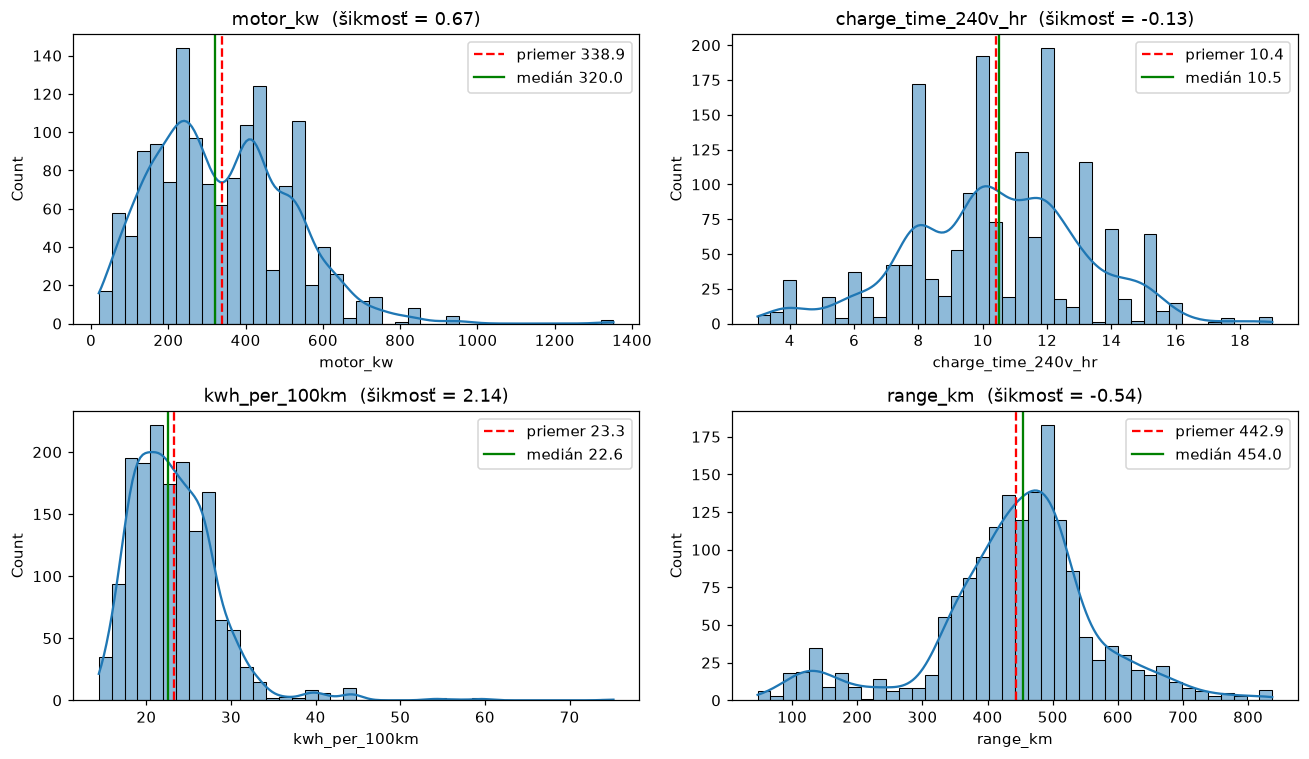

In [157]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7), dpi=110)
for ax, col in zip(axs.flat, stlpce):
    sns.histplot(df[col], bins=40, kde=True, ax=ax)
    ax.axvline(df[col].mean(), color='red', linestyle='--', label=f'priemer {df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='green', label=f'medián {df[col].median():.1f}')
    ax.set_title(f'{col}  (šikmosť = {df[col].skew():.2f})')
    ax.legend()
plt.tight_layout()
plt.show()

- **`range_km`:** väčšina áut má dojazd 350–550 km. Malá skupina s dojazdom 50–200 km sú staršie autá.
- **`motor_kw`:** má dva vrcholy (okolo 200 a 400 kW), ktoré zodpovedajú autám s jedným a s dvoma motormi.
- **`kwh_per_100km`:** väčšina áut míňa 17–30 kWh/100 km, chvost siaha až k 75.
- **`charge_time_240v_hr`:** je takmer symetrický, typicky 8–12 hodín.

## 5. Outliery

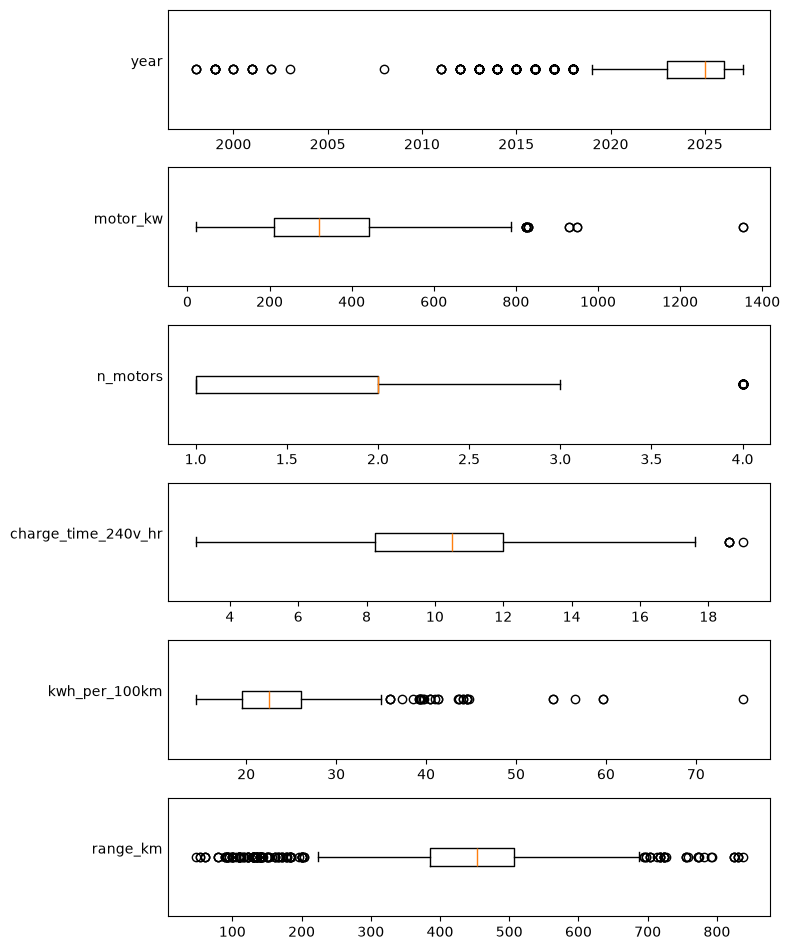

In [158]:
fig, axs = plt.subplots(len(num_col), 1, figsize=(8, 1.6 * len(num_col)), dpi=100)
for ax, col in zip(axs, num_col):
    ax.boxplot(df[col].dropna(), orientation='horizontal')
    ax.set_ylabel(col, rotation=0, ha='right')
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Boxploty ukazujú veľa krajných hodnôt. Skúsime, koľko riadkov by odstránilo bežné pravidlo
**priemer ± 2 · smerodajná odchýlka**:

In [159]:
vysledok = []
for col in ['year', 'motor_kw', 'charge_time_240v_hr', 'kwh_per_100km', 'range_km']:
    mean, std = df[col].mean(), df[col].std()
    lower, upper = mean - 2 * std, mean + 2 * std
    mimo = (~df[col].dropna().between(lower, upper)).sum()
    vysledok.append({'stĺpec': col, 'dolná hranica': round(lower, 1),
                     'horná hranica': round(upper, 1), 'mimo hraníc': mimo})
pd.DataFrame(vysledok)

,stĺpec,dolná hranica,horná hranica,mimo hraníc
0,year,2014.9,2031.8,64
1,motor_kw,-8.9,686.7,41
2,charge_time_240v_hr,5.0,15.8,82
3,kwh_per_100km,12.7,33.8,37
4,range_km,189.8,696.0,142


In [160]:
# ktoré autá sú najvýraznejšie outliery?
df.nlargest(5, 'motor_kw')[['year', 'make', 'model', 'motor_kw', 'range_km']]

,year,make,model,motor_kw,range_km
811,2025,Bugatti Rimac,Nevera,1352.0,328.0
922,2024,Bugatti Rimac,Nevera,1352.0,328.0
616,2024,Lucid,Air Sapphire AWD,950.0,687.0
1582,2027,Lucid,Air Sapphire AWD,950.0,687.0
846,2025,Lucid,Air Sapphire AWD,930.0,687.0


**Outliery podľa tohto pravidla neodstraňujeme**, pretože:

1. Nejde o chyby merania, ale o **skutočné autá** (Rimac Nevera, Lucid Air Sapphire, GMC Hummer EV).
   Keby sme ich vyhodili, model by ich nevedel predpovedať.
2. Pravidlo predpokladá symetrické rozdelenie. Pri zošikmenom `motor_kw` vychádza dolná hranica nezmyselne nízka.
3. Podľa cieľovej premennej `range_km` outliery neodstraňujeme nikdy. Prišli by sme o autá
   s najdlhším dojazdom a model by sa naučil, že také autá neexistujú.

Výnimkou sú **autá spred roku 2011**:

In [161]:
df[df['year'] < 2011][['year', 'make', 'model', 'range_km', 'kwh_per_100km']]

,year,make,model,range_km,kwh_per_100km
0,2000,Nissan,Altra EV,145.0,24.85
1,2000,Toyota,RAV4 EV,142.0,29.20
2,2001,Toyota,RAV4 EV,142.0,29.20
3,2001,Ford,Th!nk,47.0,32.31
4,2001,Ford,Explorer USPS Electric,61.0,54.06
5,2001,Nissan,Hyper-Mini,53.0,27.96
6,2002,Toyota,RAV4 EV,153.0,26.72
7,2002,Ford,Explorer USPS Electric,61.0,54.06
8,2003,Toyota,RAV4 EV,153.0,26.72
9,2001,Ford,Ranger Pickup 2WD,80.0,36.04


Sú to prvé testovacie a malosériové elektromobily (GM EV1, Toyota RAV4 EV, Ford Ranger EV…) so staršou
technológiou batérií a dojazdom väčšinou pod 170 km, teda úplne iná generácia ako dnešné elektromobily.
Z rokov 2004–2010 je v dátach navyše iba jedno auto.
Tieto autá **odstránime** na základe znalosti domény, nie štatistického pravidla.

## 6. Vzťahy medzi premennými

### 6.1 Korelácia

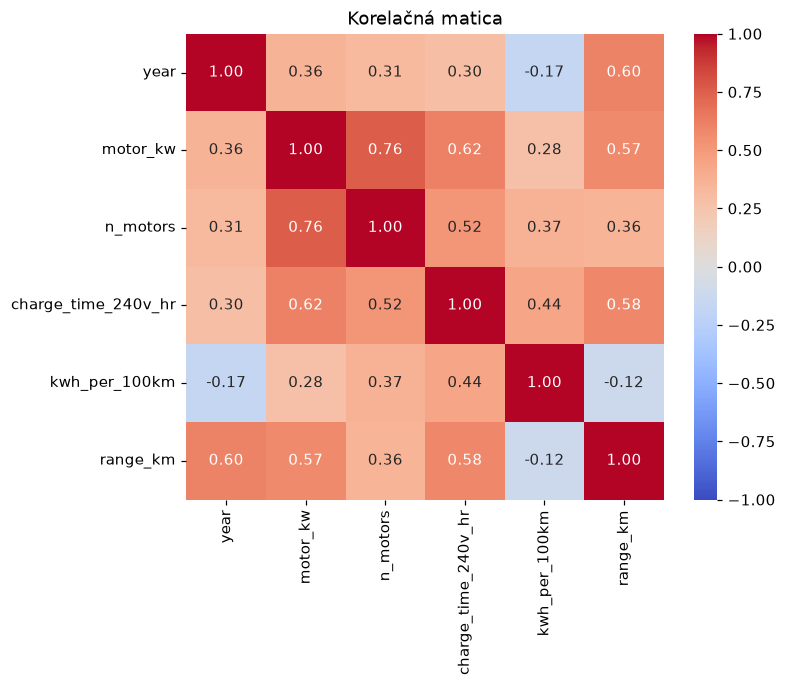

year                   0.602840
charge_time_240v_hr    0.578810
motor_kw               0.570527
n_motors               0.355008
kwh_per_100km         -0.120361
Name: range_km, dtype: float64

In [162]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(7, 5.5), dpi=110)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Korelačná matica')
plt.show()

corr['range_km'].drop('range_km').sort_values(ascending=False)

- S dojazdom najviac súvisí **rok** (0.60), **čas nabíjania** (0.58) a **výkon motora** (0.57).
- `n_motors` a `motor_kw` spolu silno korelujú (0.76). Nesú podobnú informáciu, čo zohľadníme pri výbere príznakov.
- **Spotreba (`kwh_per_100km`) má len veľmi slabú koreláciu (−0.12)**, hoci intuitívne by mala dojazd
  výrazne ovplyvňovať. Vysvetlenie je v grafe 6.3.

### 6.2 Lineárna regresia s jedným príznakom

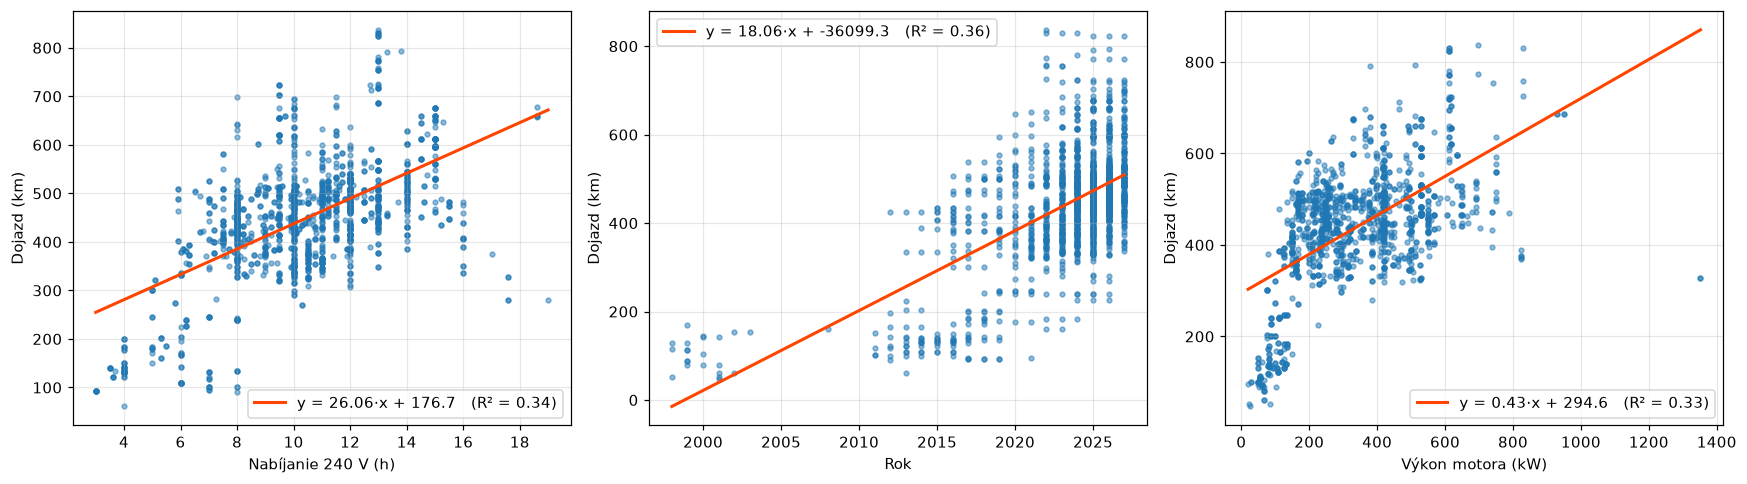

In [163]:
def graf_s_regresiou(df, x, y='range_km', xlabel=None, ylabel='Dojazd (km)', ax=None):
    d = df[[x, y]].dropna()
    a, b = np.polyfit(d[x], d[y], 1)          # priamka y = a·x + b
    r2 = d[x].corr(d[y]) ** 2                 # R² = korelácia na druhú
    ax = ax or plt.gca()
    ax.scatter(d[x], d[y], s=10, alpha=0.5)
    xs = np.linspace(d[x].min(), d[x].max(), 100)
    ax.plot(xs, a * xs + b, color='orangered', linewidth=2,
            label=f'y = {a:.2f}·x + {b:.1f}   (R² = {r2:.2f})')
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.3)
    return ax

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), dpi=110)
graf_s_regresiou(df, 'charge_time_240v_hr', xlabel='Nabíjanie 240 V (h)', ax=axs[0])
graf_s_regresiou(df, 'year', xlabel='Rok', ax=axs[1])
graf_s_regresiou(df, 'motor_kw', xlabel='Výkon motora (kW)', ax=axs[2])
plt.tight_layout()
plt.show()

- **Sklon priamky** hovorí, o koľko sa v priemere zmení dojazd: každá hodina nabíjania navyše
  (väčšia batéria) znamená približne +26 km, každý novší rok približne +18 km.
- **R² ≈ 0.3** znamená, že jeden príznak sám vysvetlí asi tretinu rozptylu dojazdu. Na dobrú
  predikciu treba **kombinovať viac príznakov**.
- Vzťahy **nie sú lineárne**: pri výkone dojazd rýchlo rastie do ~200 kW a potom sa vyrovná,
  pri roku je skok okolo 2016. To hovorí v prospech nelineárnych modelov (napr. Random Forest).

### 6.3 Dojazd podľa spotreby, výkonu a nabíjania

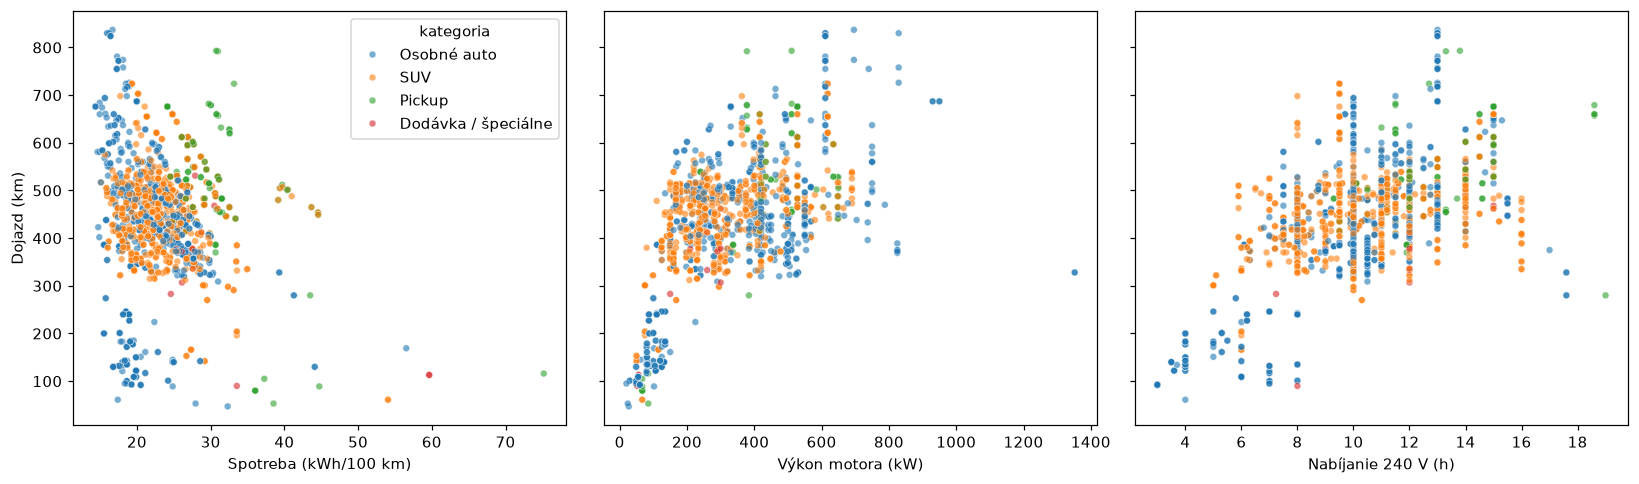

In [164]:
def kategoria(trieda):
    if 'Pickup' in trieda:
        return 'Pickup'
    if 'Sport Utility' in trieda:
        return 'SUV'
    if 'Minivan' in trieda or 'Special Purpose' in trieda:
        return 'Dodávka / špeciálne'
    return 'Osobné auto'

# pomocný stĺpec iba pre grafy, do dát pre model ho nedávame
df['kategoria'] = df['vehicle_class'].apply(kategoria)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), dpi=110, sharey=True)
for ax, col, nazov in zip(axs,
                          ['kwh_per_100km', 'motor_kw', 'charge_time_240v_hr'],
                          ['Spotreba (kWh/100 km)', 'Výkon motora (kW)', 'Nabíjanie 240 V (h)']):
    sns.scatterplot(data=df, x=col, y='range_km', hue='kategoria',
                    alpha=0.6, s=20, ax=ax, legend=(ax is axs[0]))
    ax.set_xlabel(nazov)
axs[0].set_ylabel('Dojazd (km)')
plt.tight_layout()
plt.show()

- **Spotreba:** v rámci jednej kategórie platí, že nižšia spotreba znamená dlhší dojazd. Pickupy
  však majú vysokú spotrebu **a zároveň** dlhý dojazd, lebo majú obrovské batérie. Tieto dva efekty
  sa navzájom vyrušia, preto je Pearsonova korelácia len −0.12. Spotreba je napriek tomu dôležitý
  príznak, len vzťah nie je lineárny. **Koreláciu preto nemôžeme použiť ako jediné kritérium výberu príznakov.**
- **Čas nabíjania** približne zodpovedá veľkosti batérie, ktorá v dátach priamo nie je.

## 7. Kategorické premenné a vývoj v čase

### 7.1 Vývoj dojazdu v čase

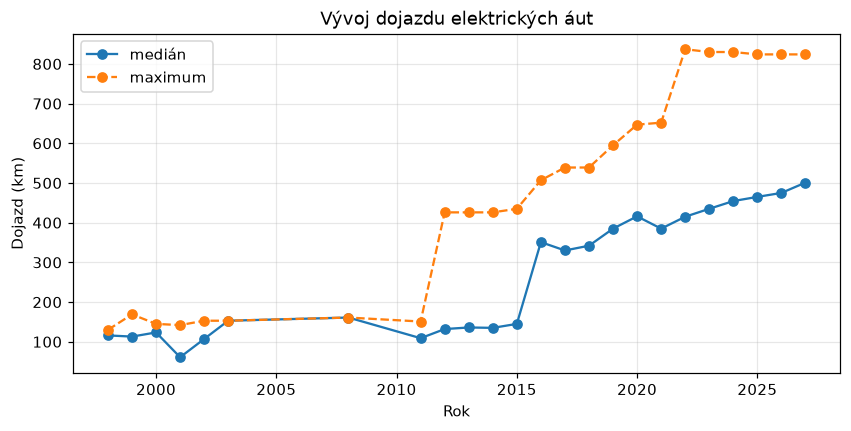

In [165]:
po_rokoch = df.groupby('year')['range_km'].agg(['median', 'max'])

plt.figure(figsize=(9, 4), dpi=110)
plt.plot(po_rokoch.index, po_rokoch['median'], marker='o', label='medián')
plt.plot(po_rokoch.index, po_rokoch['max'], marker='o', linestyle='--', label='maximum')
plt.xlabel('Rok')
plt.ylabel('Dojazd (km)')
plt.title('Vývoj dojazdu elektrických áut')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Do roku 2015 mali bežné elektromobily dojazd okolo 110–145 km. V roku 2016 nastal skok na ~350 km
a odvtedy medián rastie až k ~500 km. Rok je preto silný príznak.

### 7.2 Dojazd podľa pohonu a kategórie

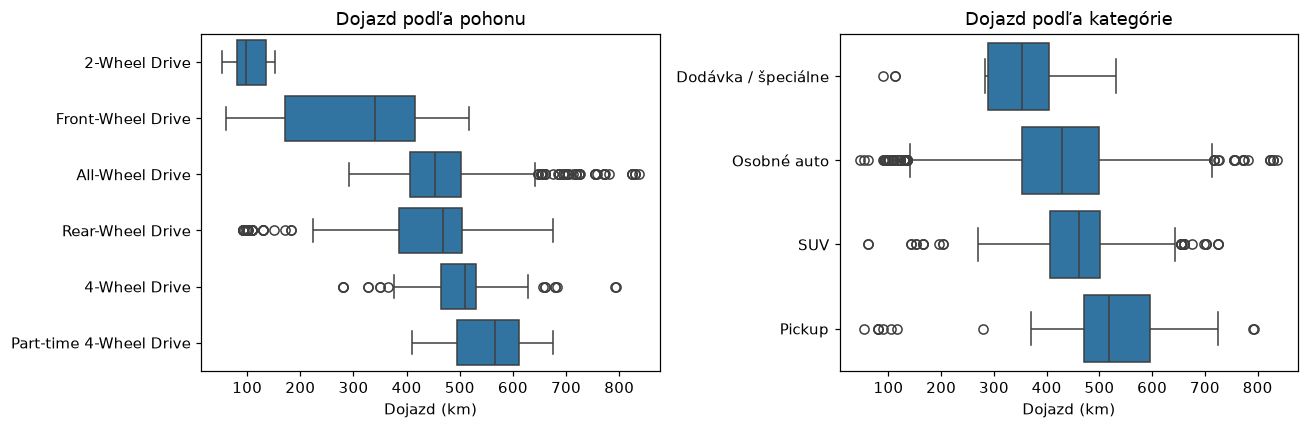

In [166]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), dpi=110)
for ax, col, nazov in zip(axs, ['drive', 'kategoria'], ['pohonu', 'kategórie']):
    poradie = df.groupby(col)['range_km'].median().sort_values().index
    sns.boxplot(data=df, x='range_km', y=col, order=poradie, ax=ax)
    ax.set_title(f'Dojazd podľa {nazov}')
    ax.set_xlabel('Dojazd (km)')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

- **Pohon:** najkratší dojazd má predný pohon, najdlhší 4×4 (hlavne veľké pickupy ako Rivian).
- **Kategória:** pickupy > SUV > osobné autá. Väčšie autá majú väčšiu batériu, a teda aj dlhší dojazd, aj keď viac míňajú.

### 7.3 Dojazd podľa značky

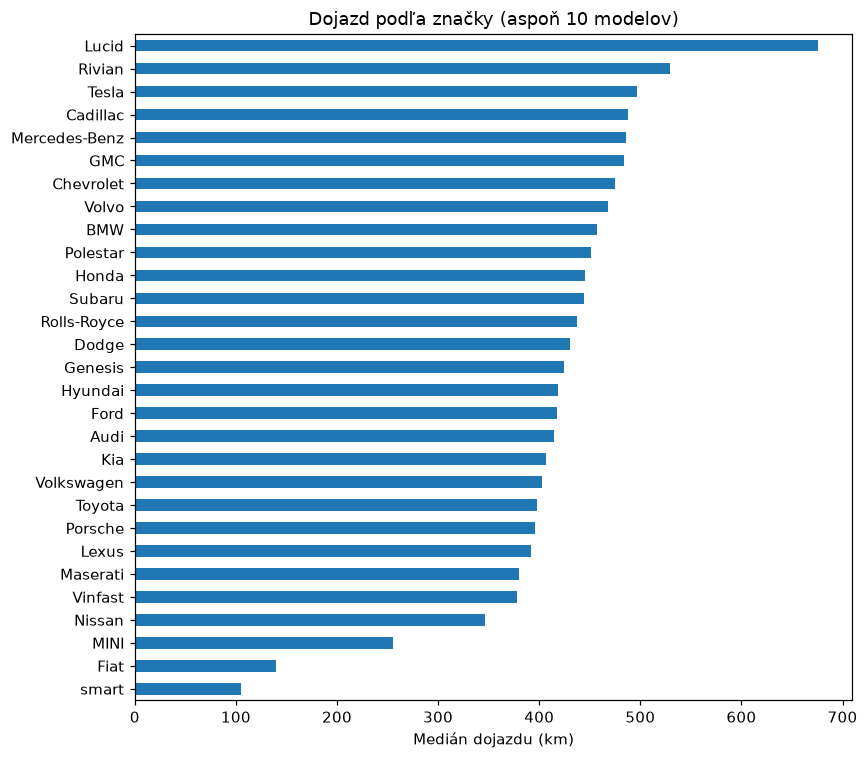

In [167]:
pocet = df['make'].value_counts()
caste = df[df['make'].isin(pocet[pocet >= 10].index)]
znacky = caste.groupby('make')['range_km'].median().sort_values()

plt.figure(figsize=(8, 7), dpi=110)
znacky.plot.barh()
plt.xlabel('Medián dojazdu (km)')
plt.ylabel('')
plt.title('Dojazd podľa značky (aspoň 10 modelov)')
plt.tight_layout()
plt.show()

Jasne vedie Lucid, za ním Rivian a Tesla. Najkratší dojazd majú malé mestské autá Fiat a smart.
Značka teda nesie informáciu nad rámec technických parametrov (napr. technológiu batérie či aerodynamiku).

## 8. Zhrnutie analýzy

- Dataset má 1608 elektrických áut a 10 stĺpcov, bez duplikátov.
- Chýbajúce hodnoty sú v stĺpcoch `motor_kw`, `n_motors`, `charge_time_240v_hr` a `drive`.
- Outliery sú skutočné autá, preto ich ponechávame. Odstránime iba staré autá spred roku 2011.
- Dojazd najviac súvisí s rokom, časom nabíjania (veľkosťou batérie) a výkonom motora.
- Vzťahy sú nelineárne a jeden príznak sám vysvetlí najviac ~⅓ rozptylu, preto bude treba
  model s viacerými príznakmi.
- Spotreba má veľmi slabú koreláciu (−0.12), no je dôležitá. Pri výbere príznakov sa nemôžeme spoliehať iba na koreláciu.
- `motor_kw` a `n_motors` nesú podobnú informáciu.

## 9. Čistenie dát pre model

Na základe analýzy pripravíme čistý dataset, z ktorého bude vychádzať preprocessing a trénovanie modelu.

### 9.1 Odstránenie starých áut a nepotrebných stĺpcov

In [168]:
data = df[df['year'] >= 2011].copy()

# model: identifikátor (stovky unikátnych hodnôt), model by sa ho naučil naspamäť
# kategoria: pomocný stĺpec len pre grafy
data = data.drop(columns=['model', 'kategoria'])

print('Odstránených riadkov:', len(df) - len(data))
print('Ostáva:', data.shape)

Odstránených riadkov: 23
Ostáva: (1585, 9)


### 9.2 Doplnenie chýbajúcich hodnôt

In [169]:
data.isna().sum()

year                     0
make                     0
vehicle_class            0
drive                    0
motor_kw               213
n_motors                51
charge_time_240v_hr      1
kwh_per_100km            0
range_km                 0
dtype: int64

Postup dopĺňania (poradie je dôležité):

1. **`n_motors`:** odvodíme z pohonu. Pohon jednej nápravy = 1 motor, 4×4 / AWD = aspoň 2 motory.
2. **`motor_kw`:** doplníme **mediánom podľa počtu motorov**. Histogram ukázal dva vrcholy
   (jeden a dva motory), takže jeden spoločný medián by bol pre obe skupiny nepresný.
3. **`charge_time_240v_hr`:** doplníme celkovým mediánom.

In [170]:
print('Medián motor_kw podľa počtu motorov:')
print(data.groupby('n_motors')['motor_kw'].median())

Medián motor_kw podľa počtu motorov:
n_motors
1.0    168.0
2.0    416.0
3.0    690.0
4.0    648.0
Name: motor_kw, dtype: float64


In [171]:
# 1. n_motors podľa pohonu
awd = data['drive'].str.contains('4-Wheel|All-Wheel')
data['n_motors'] = data['n_motors'].fillna(awd.map({True: 2, False: 1}))

# 2. motor_kw: medián v rámci skupiny s rovnakým počtom motorov
data['motor_kw'] = data['motor_kw'].fillna(
    data.groupby('n_motors')['motor_kw'].transform('median'))

# 3. charge_time_240v_hr: celkový medián
data['charge_time_240v_hr'] = data['charge_time_240v_hr'].fillna(
    data['charge_time_240v_hr'].median())

data['n_motors'] = data['n_motors'].astype(int)
data.isna().sum()

year                   0
make                   0
vehicle_class          0
drive                  0
motor_kw               0
n_motors               0
charge_time_240v_hr    0
kwh_per_100km          0
range_km               0
dtype: int64

### 9.3 Kontrola a uloženie

In [172]:
print(data.shape)
data.describe().T.round(1)

(1585, 9)


,count,mean,std,min,25%,50%,75%,max
year,1585.0,2023.7,3.2,2011.0,2023.0,2025.0,2026.0,2027.0
motor_kw,1585.0,353.6,165.1,20.0,230.0,378.0,420.0,1352.0
n_motors,1585.0,1.8,0.6,1.0,1.0,2.0,2.0,4.0
charge_time_240v_hr,1585.0,10.4,2.7,3.0,8.2,10.5,12.0,19.0
kwh_per_100km,1585.0,23.0,4.6,14.4,19.6,22.5,26.1,44.6
range_km,1585.0,447.8,120.7,61.0,389.0,455.0,507.0,837.0


In [173]:
data.to_csv('data/ev_clean.csv', index=False)
print('Uložené do data/ev_clean.csv')

Uložené do data/ev_clean.csv


## 10. Ďalšie kroky: preprocessing a model

Súbor `data/ev_clean.csv` už nemá chýbajúce hodnoty ani irelevantné riadky a stĺpce. V ďalšej časti nasleduje:

1. **Rozdelenie na X a y:** `y = range_km`, ostatné stĺpce sú príznaky.
2. **Kódovanie kategórií:** `make`, `vehicle_class`, `drive` cez one-hot encoding.
   Zriedkavé značky a triedy môžeme zlúčiť do kategórie „Other“.
3. **Train/test split:** s premiešaním, lebo dáta sú zoradené podľa roku.
4. **Škálovanie:** `StandardScaler` (je odolnejší voči outlierom ako Min-Max), iba pre lineárne
   modely, KNN či SVR. Scaler sa učí len na trénovacích dátach. Stromové modely škálovanie nepotrebujú.
5. **Výber príznakov:** overiť, či `n_motors` niečo pridáva oproti `motor_kw`.
6. **Pri lineárnych modeloch** zvážiť logaritmickú transformáciu zošikmeného `kwh_per_100km`.